In [1]:
import pygmt
import numpy as np
import pandas as pd
import shapely
import geopandas as gpd

In [2]:
# load other data
volc_file = "/Users/tz20896/Downloads/World_volcanoes.csv"
plate_file = "/Users/tz20896/Downloads/Tectonic_Plate_Boundaries/Tectonic_Plate_boundaries.shp"
town_file = "/Users/tz20896/Downloads/geonames-all-cities-with-a-population-1000/geonames-all-cities-with-a-population-1000.shp"

pop_dens_file = "/Users/tz20896/Downloads/idn-popidnpppv2b2015unadj/IDN_ppp_v2b_2015_UNadj.tif"
pop_cmap_file = "/Users/tz20896/Downloads/density_lajolla.cpt"
volcanoes_df = pd.read_csv(volc_file)
# print(volcanoes_df)

plate_df = gpd.read_file(plate_file)
plate_bounds = [geom for geom in plate_df.geometry]
bound_type = [b_type for b_type in plate_df['Boundary_T']]
# print(plate_df)

town_df = gpd.read_file(town_file)
town_coords = np.array([[town.x, town.y] for town in town_df.geometry])
town_pop = np.array([int(pop) for pop in town_df['population']])
print(town_pop)


with open("legend_spec.txt", "w") as f:
    f.write(f"N1\n")
    f.write(f"S black 0.35c - 0.4c - 0.5p,red 0.8c Unknown\n")
    # f.write(f"G 0.07c")
    f.write(f"S black 0.35c f+r+t 1c/-3/0.3c darkred thin,black 0.8c Convergent")
    # f.write(f"G 0.07c")
    f.write(f"S black 0.35c - 0.4c thin,green 0.8c Divergent")
    # f.write(f"G 0.07c")
    f.write(f"S black 0.35c f+l+s45 0.45c/-1/0.16c black 0.5p,black 0.8c Transform")


town_df.head()
# S 0.35c - 0.4c - 0.5p,black 0.8c Falla
# G 0.07c
# S 0.35c - 0.4c - 0.5p,black,- 0.8c Falla cubierta
# G 0.07c
# S 0.35c f+r+t 0.45c/-3/0.06c black 0.5p,black 0.8c Falla inversa
# G 0.07c
# S 0.35c f+r 0.45c/-5/0.08c black 0.5p,black 0.8c Falla normal
# G 0.07c
# S 0.35c f+l+s45 0.45c/-1/0.16c black 0.5p,black 0.8c Falla de rumbo sinestral

[0 0 0 ... 0 0 0]


,geoname_id,name,ascii_name,alternate_n,feature_cla,feature_cod,country_cod,cou_name_en,admin1_code,admin2_code,admin3_code,admin4_code,population,elevation,dem,timezone,modificatio,label_en,geometry
0,1213906,Seulimeum,Seulimeum,"['Selimeum', 'Seulimeum', 'Seulimeun']",P,PPLA3,None,Indonesia,01,1108,None,None,0,None,57,Asia/Jakarta,2022-12-30,Indonesia,POINT (95.57650 5.36180)
1,1214258,Parmonangan,Parmonangan,['Parmonangan'],P,PPLA3,None,Indonesia,26,1205,None,None,0,None,1194,Asia/Jakarta,2022-12-30,Indonesia,POINT (98.76370 2.10460)
2,1622278,Waiwerang,Waiwerang,"['Waewerang', 'Waiwerang']",P,PPLA3,None,Indonesia,18,5309,None,None,0,None,28,Asia/Makassar,2022-12-31,Indonesia,POINT (123.16480 -8.38840)
3,1623197,Tual,Tual,"['Toeal', 'Tual']",P,PPL,None,Indonesia,28,8172,None,None,88999,None,41,Asia/Jayapura,2022-12-31,Indonesia,POINT (132.75229 -5.62878)
4,1623385,Tongutisungi,Tongutisungi,"['Tongoete', 'Tongoete-soengi', 'Tongute-sungi...",P,PPLA3,None,Indonesia,29,8201,None,None,0,None,32,Asia/Jayapura,2022-12-30,Indonesia,POINT (127.55571 1.49813)


413
16


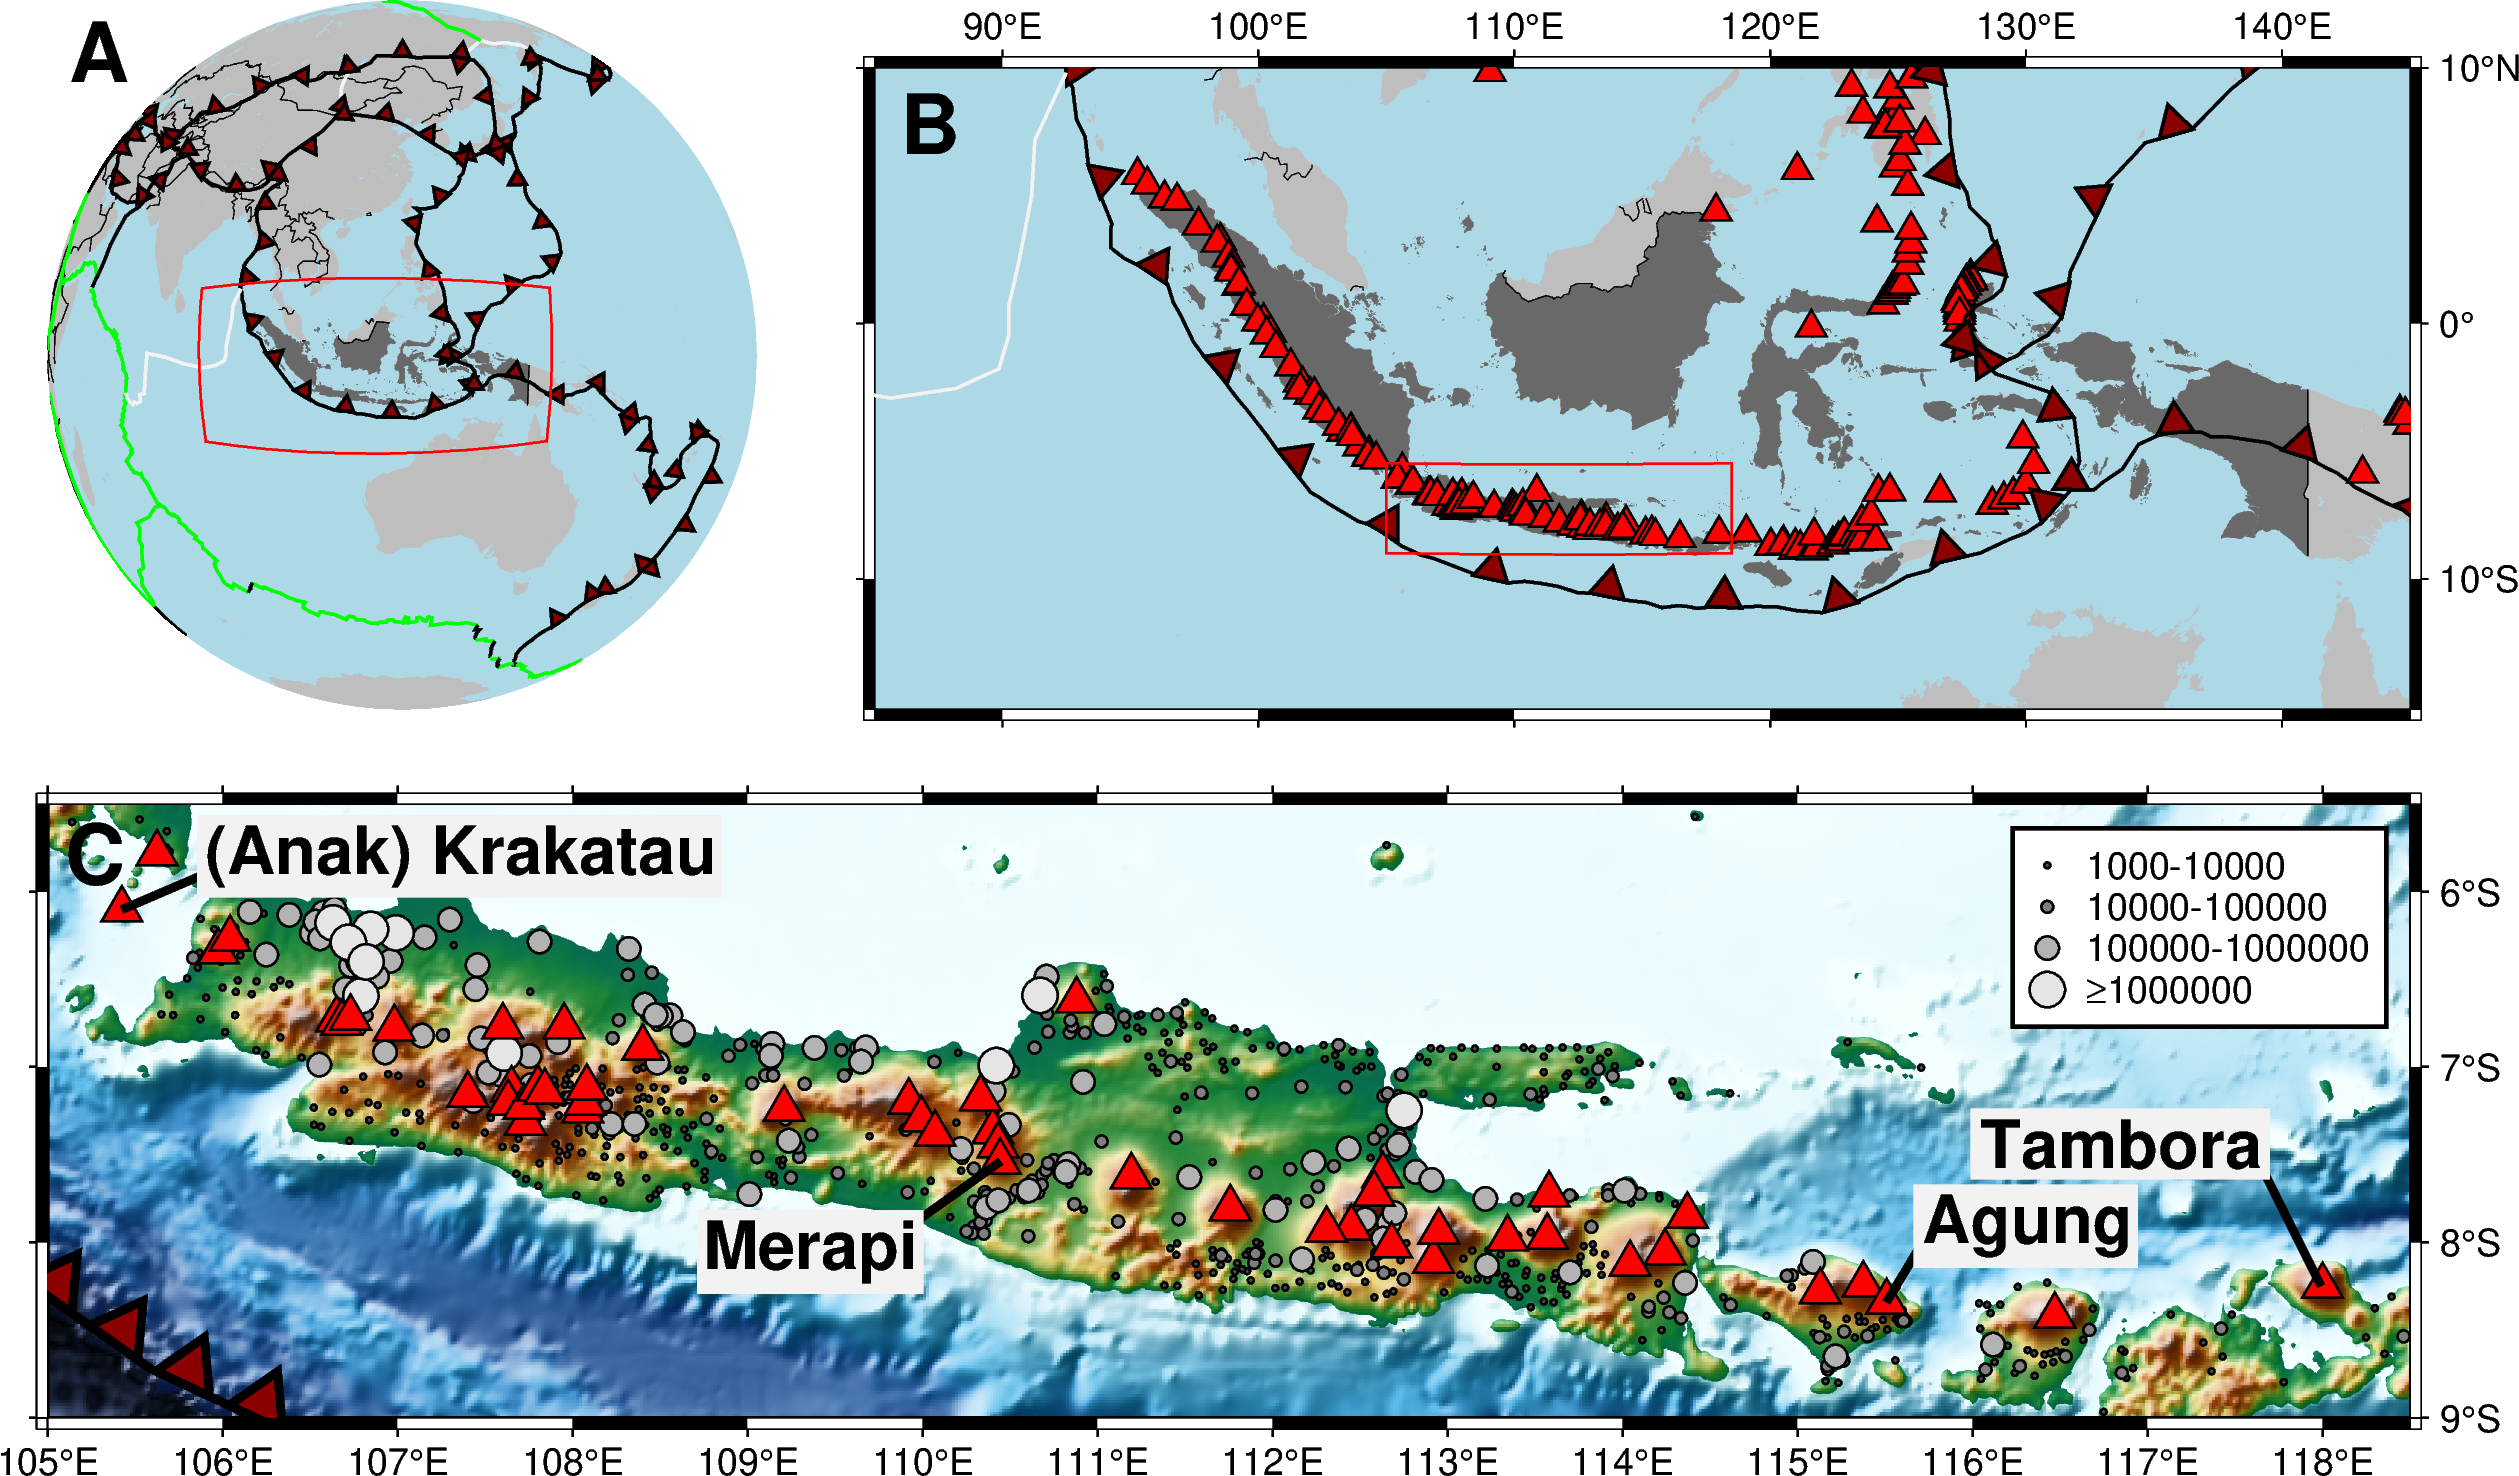

In [3]:
# # define user variables
REGION = [105,118.5,-9,-5.5]
MEAN_LON = int(np.round((REGION[0]+REGION[1])/2))
MEAN_LAT = int(np.round((REGION[2]+REGION[3])/2))
PROJECTION = "M20c"
# PERSPECTIVE = [165,30]
ZSIZE = "1c"
SHADING = True
PROJECTION_INSET = f"M5c"
AREA_THRESH = 10_000

# REGION = [10,30,76,81,-4000,2000]
# MEAN_LON = int(np.round((REGION[0]+REGION[1])/2))
# MEAN_LAT = int(np.round((REGION[2]+REGION[3])/2))
# PROJECTION = "S0/90/20c"
# PERSPECTIVE = [180,30]
# ZSIZE = "0.5c"
# SHADING = True
# PROJECTION_INSET = f"M5c"
# AREA_THRESH = 10_000

# download topo data at 30 arc sec. resolution
grid2 = pygmt.datasets.load_earth_relief(resolution="01m",region=REGION)
dgrid = pygmt.grdgradient(grid=grid2, radiance=[270, 30])
# pygmt.makecpt(cmap="gray", series=[-1.5, 0.3, 0.01])
fig = pygmt.Figure()



fig.plot(x=[0,1],
         y=[0,1],
         pen='0c,white',
         projection='X6c',
         region=[0, 1, 0, 1],)
with open("texts3.txt", "w") as f:
    f.write(f"{0.03} {0.97} 0 20p,Helvetica-Bold,black TL A\n")
fig.text(textfiles="texts3.txt", angle=True, font=True, justify=True,projection='X6c')

fig.shift_origin(xshift="0c", yshift="0c")

fig.coast(
        region="g",
        projection="G120/-1/6",
        land="gray",
        water="lightblue",
        dcw="ID+gdimgrey",
        borders="1/0.2p,black"
    )

for (line,b_type) in zip(plate_bounds,bound_type):
    x, y = line.coords.xy
    if b_type == 'Unknown':
        fig.plot(x=x, y=y, pen="thin,grey95")
    elif b_type == 'Divergent':
        fig.plot(x=x, y=y, pen="thin,green")
    elif b_type == 'Convergent':
        fig.plot(x=x, y=y, pen="thin,black",style='f0.4c/0.15c+r+t',fill="darkred",)
    elif b_type == 'Transform':
        fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c')
    
fig.plot(x= [85, 145, 145, 85, 85],
         y= [-15, -15, 10, 10, -15],
         pen='0.5p,red')


# Shift plot origin of the second map by 12.5 cm in x direction
fig.shift_origin(xshift="7c", yshift="0c")

fig.coast(frame=["xa10","ya10","wsNE"],
          region = [85,145,-15,10],
          projection= "M13c",
          land="gray",
          water="lightblue",
          dcw="ID+gdimgrey",
          borders="1/0.2p,black")

fig.plot(x = volcanoes_df['Lon'],
         y = volcanoes_df['Lat'],
         region = [85,145,-15,10],
         style="t0.3c",
         pen="0.5p,black",
         fill="red")

# for line in plate_bounds:
#     x, y = line.coords.xy
#     fig.plot(x=x, y=y, pen="thin")
make_label = [0,0,0,0]
for (line,b_type) in zip(plate_bounds,bound_type):
    x, y = line.coords.xy
    if b_type == 'Unknown':
        if make_label[0]==1:
            fig.plot(x=x, y=y, pen="thin,grey95",label='Unknown')
            make_label[0] = 0
        else:
            fig.plot(x=x, y=y, pen="thin,grey95")
    elif b_type == 'Divergent':
        if make_label[1]==1:
            fig.plot(x=x, y=y, pen="thin,green",label='Divergent')
            make_label[1]=0
        else:
            fig.plot(x=x, y=y, pen="thin,green")
    elif b_type == 'Convergent':
        if make_label[2]==1:
            fig.plot(x=x, y=y, pen="thin,black",style='f1c/0.3c+r+b',fill="darkred",label='Convergent')
            make_label[2]=0
        else:
            fig.plot(x=x, y=y, pen="thin,black",style='f1c/0.3c+r+t',fill="darkred")
    elif b_type == 'Transform':
        if make_label[3]==1:
            fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c',label='Transform')
            make_label[3]=0
        else:
            fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c')

# [105,117,-9,-5.5]
fig.plot(x= [105, 118.5, 118.5,105 ,105],
         y= [-9, -9, -5.5, -5.5, -9],
         pen='0.5p,red')

# fig.legend(spec='legend_spec.txt')

with open("texts3.txt", "w") as f:
    f.write(f"{86} {9} 0 20p,Helvetica-Bold,black TL B\n")
fig.text(textfiles="texts3.txt", angle=True, font=True, justify=True,)
# Shift plot origin of the second map by 12.5 cm in x direction
fig.shift_origin(xshift="-7c", yshift="-6c")

fig.grdview(grid=grid2,
            frame=["xa1","ya1","wSnE"],
            projection=PROJECTION,
            region=REGION,
            zsize=ZSIZE,
            surftype="s",
            cmap="geo",
            shading=SHADING,
            plane="-6000+gazure",
            )
sel10000 = (town_pop>=10_000)
sel100000 = (town_pop>=100_000)
sel1000000 = (town_pop>=1_000_000)
sel10000000 = (town_pop>=10_000_000)
print(np.size(np.argwhere(sel10000)))
print(np.size(np.argwhere(sel1000000)))

fig.plot(x = town_coords[:,0],
         y = town_coords[:,1],
         style = 'c',
         size= np.repeat(0.05,np.size(np.argwhere(town_coords[:,0]))),
         fill = "grey30",
         pen = "0.5p,black",
         label = "1000-10000+S0.05",
         )

fig.plot(x = town_coords[sel10000,0],
         y = town_coords[sel10000,1],
         style = 'c',
         size= np.repeat(0.1,np.size(np.argwhere(sel10000))),
         fill = "grey50",
         pen = "0.5p,black",
         label = "10000-100000+S0.1",
         )

fig.plot(x = town_coords[sel100000,0],
         y = town_coords[sel100000,1],
         style = 'c',
         size= np.repeat(0.2,np.size(np.argwhere(sel100000))),
         fill = "grey70",
         pen = "0.5p,black",
         label = "100000-1000000+S0.2",
         )

fig.plot(x = town_coords[sel1000000,0],
         y = town_coords[sel1000000,1],
         style = 'c',
         size= np.repeat(0.3,np.size(np.argwhere(sel1000000))),
         fill = "grey90",
         pen = "0.5p,black",
         label = "≥1000000+S0.3",
         )

# fig.plot(x = town_coords[sel10000000,0],
#          y = town_coords[sel10000000,1],
#          style = 'c',
#          size= np.repeat(0.125,np.size(np.argwhere(sel10000000))),
#          fill = "grey80",
#          pen = "0.5p,black",
#          )

fig.plot(x = volcanoes_df['Lon'],
         y = volcanoes_df['Lat'],
         region=REGION,
         style="t0.4c",
         pen="0.5p,black",
         fill="red")

for (line,b_type) in zip(plate_bounds,bound_type):
    x, y = line.coords.xy
    if b_type == 'Unknown':
        fig.plot(x=x, y=y, pen="thin,white")
    elif b_type == 'Divergent':
        fig.plot(x=x, y=y, pen="thin,green")
    elif b_type == 'Convergent':
        fig.plot(x=x, y=y, pen="2p,black",style='f0.8c/0.5c+r+t',fill="darkred",)
    elif b_type == 'Transform':
        fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c')

# texts
# Create space-delimited file
with open("texts.txt", "w") as f:
    f.write(f"{110.445} {-7.54}  0 16p,Helvetica-Bold,black TR Merapi\n")
fig.text(textfiles="texts.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.7/0.5+v2p,black',fill='gray95')

with open("texts2.txt", "w") as f:
    f.write(f"{115.507} {-8.343} 0 16p,Helvetica-Bold,black BL Agung\n")
fig.text(textfiles="texts2.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.3/0.5+v2p,black',fill='grey95')

with open("texts2.txt", "w") as f:
    f.write(f"{105.423} {-6.102} 0 16p,Helvetica-Bold,black BL (Anak) Krakatau\n")
fig.text(textfiles="texts2.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.7/0.3+v2p,black',fill='grey95')

with open("texts2.txt", "w") as f:
    f.write(f"{117.99} {-8.249} 0 16p,Helvetica-Bold,black BR Tambora\n")
fig.text(textfiles="texts2.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.5/1+v2p,black',fill='grey95')

with open("texts3.txt", "w") as f:
    f.write(f"{105.1} {-5.6} 0 20p,Helvetica-Bold,black TL C\n")
fig.text(textfiles="texts3.txt", angle=True, font=True, justify=True)


fig.legend(position="jTR+o0.2c/0.2c",box='+gwhite+p1p',S=1)
# fig.savefig("/Users/tz20896/Documents/PhD/00Thesis/additional_figgures/Sunda_arc.pdf")


fig.show()



In [4]:
# # define user variables
REGION = [105,118.5,-9,-5.5]
MEAN_LON = int(np.round((REGION[0]+REGION[1])/2))
MEAN_LAT = int(np.round((REGION[2]+REGION[3])/2))
PROJECTION = "M20c"
# PERSPECTIVE = [165,30]
ZSIZE = "1c"
SHADING = True
PROJECTION_INSET = f"M5c"
AREA_THRESH = 10_000

# REGION = [10,30,76,81,-4000,2000]
# MEAN_LON = int(np.round((REGION[0]+REGION[1])/2))
# MEAN_LAT = int(np.round((REGION[2]+REGION[3])/2))
# PROJECTION = "S0/90/20c"
# PERSPECTIVE = [180,30]
# ZSIZE = "0.5c"
# SHADING = True
# PROJECTION_INSET = f"M5c"
# AREA_THRESH = 10_000

# download topo data at 30 arc sec. resolution
grid2 = pygmt.datasets.load_earth_relief(resolution="01m",region=REGION)
dgrid = pygmt.grdgradient(grid=grid2, radiance=[270, 30])
# pygmt.makecpt(cmap="gray", series=[-1.5, 0.3, 0.01])



fig = pygmt.Figure()



fig.plot(x=[0,1],
         y=[0,1],
         pen='0c,white',
         projection='X6c',
         region=[0, 1, 0, 1],)
with open("texts3.txt", "w") as f:
    f.write(f"{0.03} {0.97} 0 20p,Helvetica-Bold,black TL A\n")
fig.text(textfiles="texts3.txt", angle=True, font=True, justify=True,projection='X6c')

fig.shift_origin(xshift="0c", yshift="0c")

fig.coast(
        region="g",
        projection="G120/-1/6",
        land="gray",
        water="lightblue",
        dcw="ID+gdimgrey",
        borders="1/0.2p,black"
    )

for (line,b_type) in zip(plate_bounds,bound_type):
    x, y = line.coords.xy
    if b_type == 'Unknown':
        fig.plot(x=x, y=y, pen="thin,grey95")
    elif b_type == 'Divergent':
        fig.plot(x=x, y=y, pen="thin,green")
    elif b_type == 'Convergent':
        fig.plot(x=x, y=y, pen="thin,black",style='f0.4c/0.15c+r+t',fill="darkred",)
    elif b_type == 'Transform':
        fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c')
    
fig.plot(x= [85, 145, 145, 85, 85],
         y= [-15, -15, 10, 10, -15],
         pen='0.5p,red')


# Shift plot origin of the second map by 12.5 cm in x direction
fig.shift_origin(xshift="7c", yshift="0c")

fig.coast(frame=["xa10","ya10","wsNE"],
          region = [85,145,-15,10],
          projection= "M13c",
          land="gray",
          water="lightblue",
          dcw="ID+gdimgrey",
          borders="1/0.2p,black")

fig.plot(x = volcanoes_df['Lon'],
         y = volcanoes_df['Lat'],
         region = [85,145,-15,10],
         style="t0.3c",
         pen="0.5p,black",
         fill="red")

# for line in plate_bounds:
#     x, y = line.coords.xy
#     fig.plot(x=x, y=y, pen="thin")
make_label = [0,0,0,0]
for (line,b_type) in zip(plate_bounds,bound_type):
    x, y = line.coords.xy
    if b_type == 'Unknown':
        if make_label[0]==1:
            fig.plot(x=x, y=y, pen="thin,grey95",label='Unknown')
            make_label[0] = 0
        else:
            fig.plot(x=x, y=y, pen="thin,grey95")
    elif b_type == 'Divergent':
        if make_label[1]==1:
            fig.plot(x=x, y=y, pen="thin,green",label='Divergent')
            make_label[1]=0
        else:
            fig.plot(x=x, y=y, pen="thin,green")
    elif b_type == 'Convergent':
        if make_label[2]==1:
            fig.plot(x=x, y=y, pen="thin,black",style='f1c/0.3c+r+b',fill="darkred",label='Convergent')
            make_label[2]=0
        else:
            fig.plot(x=x, y=y, pen="thin,black",style='f1c/0.3c+r+t',fill="darkred")
    elif b_type == 'Transform':
        if make_label[3]==1:
            fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c',label='Transform')
            make_label[3]=0
        else:
            fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c')

# [105,117,-9,-5.5]
fig.plot(x= [105, 118.5, 118.5,105 ,105],
         y= [-9, -9, -5.5, -5.5, -9],
         pen='0.5p,red')

# fig.legend(spec='legend_spec.txt')

with open("texts3.txt", "w") as f:
    f.write(f"{86} {9} 0 20p,Helvetica-Bold,black TL B\n")
fig.text(textfiles="texts3.txt", angle=True, font=True, justify=True,)
# Shift plot origin of the second map by 12.5 cm in x direction
fig.shift_origin(xshift="-7c", yshift="-6c")

pygmt.makecpt(cmap="gray", series=[-1.5, 0.3, 0.01])
fig.grdimage(grid=dgrid,
            frame=["xa1","ya1","wSnE"],
            projection=PROJECTION,
            region=REGION,
            cmap=True,
            )

fig.grdimage(grid=pop_dens_file,
            frame=["xa1","ya1","wSnE"],
            projection=PROJECTION,
            region=REGION,
            cmap=pop_cmap_file,
            )

fig.plot(x = volcanoes_df['Lon'],
         y = volcanoes_df['Lat'],
         region=REGION,
         style="t0.4c",
         pen="0.5p,black",
         fill="red")

for (line,b_type) in zip(plate_bounds,bound_type):
    x, y = line.coords.xy
    if b_type == 'Unknown':
        fig.plot(x=x, y=y, pen="thin,white")
    elif b_type == 'Divergent':
        fig.plot(x=x, y=y, pen="thin,green")
    elif b_type == 'Convergent':
        fig.plot(x=x, y=y, pen="2p,black",style='f0.8c/0.5c+r+t',fill="darkred",)
    elif b_type == 'Transform':
        fig.plot(x=x, y=y, pen="thin,black",style='f5c/1c+l+s45+o2.25c')

# texts
# Create space-delimited file
with open("texts.txt", "w") as f:
    f.write(f"{110.445} {-7.54}  0 16p,Helvetica-Bold,black TR Merapi\n")
fig.text(textfiles="texts.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.7/0.5+v2p,black',fill='gray95')

with open("texts2.txt", "w") as f:
    f.write(f"{115.507} {-8.343} 0 16p,Helvetica-Bold,black BL Agung\n")
fig.text(textfiles="texts2.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.3/0.5+v2p,black',fill='grey95')

with open("texts2.txt", "w") as f:
    f.write(f"{105.423} {-6.102} 0 16p,Helvetica-Bold,black BL (Anak) Krakatau\n")
fig.text(textfiles="texts2.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.7/0.3+v2p,black',fill='grey95')

with open("texts2.txt", "w") as f:
    f.write(f"{117.99} {-8.249} 0 16p,Helvetica-Bold,black BR Tambora\n")
fig.text(textfiles="texts2.txt", angle=True, font=True, justify=True,region=REGION,offset='j0.5/1+v2p,black',fill='grey95')

with open("texts3.txt", "w") as f:
    f.write(f"{105.1} {-5.6} 0 20p,Helvetica-Bold,black TL C\n")
fig.text(textfiles="texts3.txt", angle=True, font=True, justify=True)


fig.legend(position="jTR+o0.2c/0.2c",box='+gwhite+p1p',S=1)
fig.savefig("/Users/tz20896/Documents/PhD/00Thesis/additional_figgures/Sunda_arc_pop_dens.pdf")


fig.show()

